# GNSS under the sky: real satellites, DOP, terrain and Bpv heights

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/gnss_sky_en.ipynb)

**OpenSkyLab · notebook for the visual** [GNSS under the sky](https://openskylab.space/edu_viz_gnss_sky.html) · [česká verze](gnss_sky_cs.ipynb)

The visual shows how the number and layout of satellites set the DOP, what obstacles and the elevation mask do and why GNSS height is less accurate than position. Here you compute the positions of real GPS, Galileo, GLONASS and BeiDou satellites from broadcast ephemerides, the real horizon in the Vltava valley from the ČÚZK terrain model, and the conversion from ellipsoidal height to Bpv height from survey control points.

**Goal:** draw the real GNSS sky over Suchdol, compute HDOP, VDOP and PDOP over a day, assess the effect of a forest and a deep valley, find the nearest CZEPOS reference station and convert an RTK height to Bpv.

**Data:** broadcast ephemerides of GPS, Galileo, GLONASS and BeiDou satellites for one day (RINEX navigation file merged by the IGS, BKG archive, about 1.3 MB); DMR 5G (ČÚZK) for the valley horizon; CZEPOS network stations and densification survey points with both Bpv height and ETRS89 ellipsoidal height from the ČÚZK BodovaPole service.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 50 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and satellite orbits

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, gzip, time, requests
from datetime import datetime, timedelta, timezone, date
from functools import lru_cache
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Window of a ČÚZK raster (dmr5g, dmp1g, dmp_obrazova_korelace) in S-JTSK (EPSG:5514), heights in Bpv.
    Returns the height array (row 0 = north) and its transform."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

DAY = (datetime.now(timezone.utc) - timedelta(days=1)).date()   # ◀ parameter: day (UTC), default is yesterday; try e.g. date(2026, 9, 1)
doy = DAY.timetuple().tm_yday
NAV_FILE = f"BRDC00IGS_R_{DAY.year}{doy:03d}0000_01D_MN.rnx.gz"
if not os.path.exists(NAV_FILE):
    url = f"https://igs.bkg.bund.de/root_ftp/IGS/BRDC/{DAY.year}/{doy:03d}/{NAV_FILE}"
    for attempt in range(4):
        try:
            r = requests.get(url, timeout=120)
            if r.ok:
                open(NAV_FILE, "wb").write(r.content); break
            print("BKG:", r.status_code, "– retrying")
        except requests.RequestException as e:
            print("BKG:", type(e).__name__, "– retrying")
        time.sleep(5 * (attempt + 1))
    else:
        raise RuntimeError(f"Cannot download {NAV_FILE}. The daily file appears only after the day ends (UTC); try an earlier DAY.")

SYSTEMS = {"G": "GPS", "E": "Galileo", "R": "GLONASS", "C": "BeiDou"}
def num(s):
    s = s.strip().replace("D", "E")
    return float(s) if s else 0.0
with gzip.open(NAV_FILE, "rt") as fh:
    lines = fh.read().splitlines()
i = next(k for k, l in enumerate(lines) if "END OF HEADER" in l) + 1
EPH = []
while i < len(lines):
    l = lines[i]
    n = 4 if l[0] in "RS" else 8                     # GLONASS and SBAS records have 4 lines, the others 8
    rec = lines[i:i + n]; i += n
    if l[0] not in SYSTEMS:
        continue
    t = datetime(int(l[4:8]), int(l[9:11]), int(l[12:14]), int(l[15:17]), int(l[18:20]), int(l[21:23]), tzinfo=timezone.utc)
    v = [num(l[23 + 19 * k:42 + 19 * k]) for k in range(3)] + [num(x[4 + 19 * k:23 + 19 * k]) for x in rec[1:] for k in range(4)]
    if (v[6] if l[0] == "R" else v[24]) == 0:       # only messages that flag the satellite as healthy
        EPH.append((l[:3], l[0], t, v))
eph = pd.DataFrame([(s, SYSTEMS[k], t) for s, k, t, v in EPH], columns=["satellite", "system", "time"])
print(f"{NAV_FILE}: {len(eph)} navigation messages")
print(eph.groupby("system").agg(satellites=("satellite", "nunique"), messages=("satellite", "size")).to_string())

BRDC00IGS_R_20263010000_01D_MN.rnx.gz: 14318 navigation messages
         satellites  messages
system                       
BeiDou           37       888
GLONASS          24      1144
GPS              32       457
Galileo          28     11829


## 2. From an ephemeris to a satellite position

Every satellite broadcasts its ephemeris: GPS, Galileo and BeiDou send Keplerian orbital elements with corrections (semi-major axis, eccentricity, inclination, node longitude, argument of latitude and their rates), GLONASS sends position, velocity and acceleration at one instant, from which the orbit is computed by numerical integration. The receiver computes the satellite position from them, and its own position from that. An ephemeris is valid only for a few hours around its reference time, so new ones are broadcast: GPS about every 2 h, BeiDou every hour, GLONASS every 30 min, Galileo even more often. The computation following the GPS interface specification (IS-GPS-200) and the GLONASS ICD gives the position in Earth-fixed coordinates (ECEF).

In [3]:
GPS0 = datetime(1980, 1, 6, tzinfo=timezone.utc)
def gps_seconds(t_utc):
    return (t_utc - GPS0).total_seconds() + 18          # GPS time is 18 s ahead of UTC (leap seconds)

MU = {"G": 3.986005e14, "E": 3.986004418e14, "C": 3.986004418e14}      # Earth's gravitational parameter (m³/s²) by system
WE = {"G": 7.2921151467e-5, "E": 7.2921151467e-5, "C": 7.292115e-5}    # Earth rotation (rad/s)

def kepler(sat, v, tg):
    """Position of a GPS, Galileo or BeiDou satellite (ECEF, m) at GPS time tg from Keplerian elements."""
    s = sat[0]
    crs, dn, m0, cuc, e, cus, sqa, toe, cic, om0, cis, i0, crc, w, omd, idot = v[4:20]
    tk = (tg - (14 if s == "C" else 0)) % 604800 - toe      # BeiDou has its own time, 14 s behind GPS
    tk = (tk + 302400) % 604800 - 302400                     # across the week boundary
    a = sqa ** 2
    M = m0 + (np.sqrt(MU[s] / a ** 3) + dn) * tk              # mean anomaly
    E = M
    for _ in range(10):
        E = M + e * np.sin(E)                                 # Kepler's equation
    phi = np.arctan2(np.sqrt(1 - e * e) * np.sin(E), np.cos(E) - e) + w
    u = phi + cus * np.sin(2 * phi) + cuc * np.cos(2 * phi)
    r = a * (1 - e * np.cos(E)) + crs * np.sin(2 * phi) + crc * np.cos(2 * phi)
    inc = i0 + idot * tk + cis * np.sin(2 * phi) + cic * np.cos(2 * phi)
    x, y = r * np.cos(u), r * np.sin(u)
    if s == "C" and (int(sat[1:]) <= 5 or int(sat[1:]) >= 59):   # geostationary BeiDou: special procedure (−5° tilt)
        om = om0 + omd * tk - WE[s] * toe
        X, Y, Z = x * np.cos(om) - y * np.cos(inc) * np.sin(om), x * np.sin(om) + y * np.cos(inc) * np.cos(om), y * np.sin(inc)
        f5, c, sn = np.radians(-5), np.cos(WE[s] * tk), np.sin(WE[s] * tk)
        Y, Z = Y * np.cos(f5) + Z * np.sin(f5), -Y * np.sin(f5) + Z * np.cos(f5)
        return np.array([c * X + sn * Y, -sn * X + c * Y, Z])
    om = om0 + (omd - WE[s]) * tk - WE[s] * toe
    return np.array([x * np.cos(om) - y * np.cos(inc) * np.sin(om), x * np.sin(om) + y * np.cos(inc) * np.cos(om), y * np.sin(inc)])

def glonass(v, t_ref, tg):
    """Position of a GLONASS satellite (ECEF, m): integration of motion with J2 from the broadcast state (Runge–Kutta, step up to 60 s)."""
    y = np.array([v[3], v[7], v[11], v[4], v[8], v[12]]) * 1000.0
    acc = np.array([v[5], v[9], v[13]]) * 1000.0
    mu, ae, j2, we = 3.9860044e14, 6378136.0, 1.0826257e-3, 7.292115e-5
    def f(y):
        x, yy, z, vx, vy, vz = y
        r = np.sqrt(x * x + yy * yy + z * z); k = 1.5 * j2 * mu * ae ** 2 / r ** 5
        return np.array([vx, vy, vz,
                         -mu * x / r ** 3 - k * x * (1 - 5 * z * z / r ** 2) + we ** 2 * x + 2 * we * vy + acc[0],
                         -mu * yy / r ** 3 - k * yy * (1 - 5 * z * z / r ** 2) + we ** 2 * yy - 2 * we * vx + acc[1],
                         -mu * z / r ** 3 - k * z * (3 - 5 * z * z / r ** 2) + acc[2]])
    n = max(int(np.ceil(abs(tg - t_ref) / 60)), 1); h = (tg - t_ref) / n
    for _ in range(n):
        k1 = f(y); k2 = f(y + h / 2 * k1); k3 = f(y + h / 2 * k2); k4 = f(y + h * k3)
        y = y + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return y[:3]

BY_SAT = {}
for sat, s, t, v in EPH:          # reference time of the message in GPS seconds; GLONASS uses UTC, BeiDou its own time
    t_ref = gps_seconds(t) if s == "R" else (t - GPS0).total_seconds() + (14 if s == "C" else 0)
    BY_SAT.setdefault(sat, {})[t_ref] = v
MAX_AGE = {"G": 4 * 3600, "E": 4 * 3600, "C": 4 * 3600, "R": 3600}

@lru_cache(maxsize=None)
def sat_pos(sat, tg, rank=0):
    """Satellite position at tg from the nearest ephemeris (rank=1: from the second nearest); None if none is valid."""
    refs = sorted(BY_SAT[sat], key=lambda r: abs(r - tg))
    if len(refs) <= rank or abs(refs[rank] - tg) > MAX_AGE[sat[0]]:
        return None
    v = BY_SAT[sat][refs[rank]]
    return glonass(v, refs[rank], tg) if sat[0] == "R" else kepler(sat, v, tg)

HOUR = 12          # ◀ parameter: hour of the check (UTC)
RANK = 1           # ◀ parameter: which further ephemeris to compare with (1 = neighbouring, 3 = three further)
t_check = gps_seconds(datetime(DAY.year, DAY.month, DAY.day, HOUR, 0, tzinfo=timezone.utc))
rows = []
for sat, msgs in BY_SAT.items():
    refs = sorted(msgs, key=lambda r: abs(r - t_check))
    if len(refs) <= RANK:
        continue
    p = [glonass(msgs[r], r, t_check) if sat[0] == "R" else kepler(sat, msgs[r], t_check) for r in (refs[0], refs[RANK])]
    rows.append((SYSTEMS[sat[0]], sat, np.linalg.norm(p[0]) / 1000, abs(refs[RANK] - t_check) / 3600, np.linalg.norm(p[0] - p[1])))
chk = pd.DataFrame(rows, columns=["system", "satellite", "km", "h", "m"])
print(f"{DAY} {HOUR}:00 UTC, position from the nearest ephemeris and from the one {RANK} step(s) further:")
chk.groupby("system").agg(satellites=("satellite", "size"), **{"distance from Earth's centre (km), median": ("km", "median"),
                          "age of the compared ephemeris (h), median": ("h", "median"), "position difference (m), median": ("m", "median"),
                          "position difference (m), max": ("m", "max")}).round(1)

2026-10-28 12:00 UTC, position from the nearest ephemeris and from the one 1 step(s) further:


,satellites,"distance from Earth's centre (km), median","age of the compared ephemeris (h), median","position difference (m), median","position difference (m), max"
system,,,,,
BeiDou,37,27909.3,1.0,0.2,0.6
GLONASS,24,25512.0,0.2,0.9,1043.6
GPS,32,26588.9,2.0,0.6,3.0
Galileo,28,29603.7,0.2,0.1,0.4


> **✏️ Task 1.** How far from Earth's centre do the satellites of each system orbit? Why does BeiDou also have satellites much higher (geostationary and on inclined geosynchronous orbits)? By how many metres does the position of the same satellite differ between two neighbouring ephemerides? Set `RANK = 3` and then 6 and watch the age of the compared ephemeris and the position difference. Why is the compared ephemeris much older for GPS than for Galileo at the same `RANK`? How does the difference grow with age, and why does it grow faster for GLONASS than for GPS (a broadcast state and integration, or orbital elements with corrections)? Why must ephemerides be broadcast again and again?

*Your answer:* 

2026-10-28 12:00 UTC: 32 satellites above the 10° mask: {'GPS': 10, 'BeiDou': 8, 'GLONASS': 7, 'Galileo': 7}


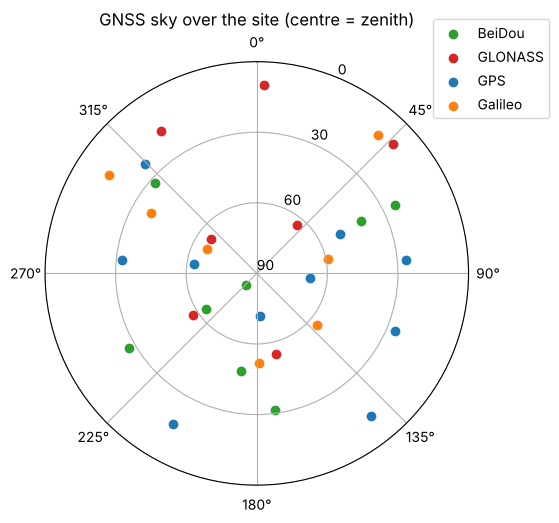

In [4]:
A, F = 6378137.0, 1 / 298.257223563
def ecef(lat, lon, h):
    la, lo = np.radians(lat), np.radians(lon); e2 = F * (2 - F); N = A / np.sqrt(1 - e2 * np.sin(la) ** 2)
    return np.array([(N + h) * np.cos(la) * np.cos(lo), (N + h) * np.cos(la) * np.sin(lo), (N * (1 - e2) + h) * np.sin(la)])

def az_el(t_utc, lat, lon, h=300.0):
    """Azimuth and elevation (°) of all satellites at time t_utc for site lat, lon, h (ellipsoidal height)."""
    tg = gps_seconds(t_utc)
    la, lo = np.radians(lat), np.radians(lon)
    enu = np.array([[-np.sin(lo), np.cos(lo), 0],
                    [-np.sin(la) * np.cos(lo), -np.sin(la) * np.sin(lo), np.cos(la)],
                    [np.cos(la) * np.cos(lo), np.cos(la) * np.sin(lo), np.sin(la)]])
    site = ecef(lat, lon, h)
    rows = []
    for sat in BY_SAT:
        p = sat_pos(sat, tg)
        if p is None: continue
        d = enu @ (p - site)
        rows.append((sat, SYSTEMS[sat[0]], np.degrees(np.arctan2(d[0], d[1])) % 360, np.degrees(np.arcsin(d[2] / np.linalg.norm(d)))))
    return pd.DataFrame(rows, columns=["satellite", "system", "az", "el"])

LAT, LON = 50.130, 14.373          # ◀ parameter: site (Suchdol campus)
T0 = datetime(DAY.year, DAY.month, DAY.day, tzinfo=timezone.utc)
T_SKY = T0 + timedelta(hours=12)   # ◀ parameter: time of the sky plot (UTC)
sky = az_el(T_SKY, LAT, LON)
mask = 10                          # ◀ parameter: elevation mask (°)
vis = sky[sky.el > mask]
print(f"{T_SKY:%Y-%m-%d %H:%M} UTC: {len(vis)} satellites above the {mask}° mask:", vis.system.value_counts().to_dict())
COL = {"GPS": "tab:blue", "Galileo": "tab:orange", "GLONASS": "tab:red", "BeiDou": "tab:green"}
fig = plt.figure(figsize=(5.5, 5.5)); ax = fig.add_subplot(projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1); ax.set_rlim(90, 0); ax.set_rticks([0, 30, 60, 90])
for s, g in vis.groupby("system"):
    ax.scatter(np.radians(g.az), g.el, c=COL[s], label=s)
ax.legend(loc="lower left", bbox_to_anchor=(0.9, 0.85)); ax.set_title("GNSS sky over the site (centre = zenith)"); plt.show()

## 3. DOP over a day

We compute DOP from geometry: each satellite gives a row of the matrix G with the unit direction vector (east, north, up) and a one for the receiver clock (each system has its own clock offset). Q = (GᵀG)⁻¹, HDOP = √(Q_EE + Q_NN), VDOP = √Q_UU, PDOP = √(Q_EE + Q_NN + Q_UU).

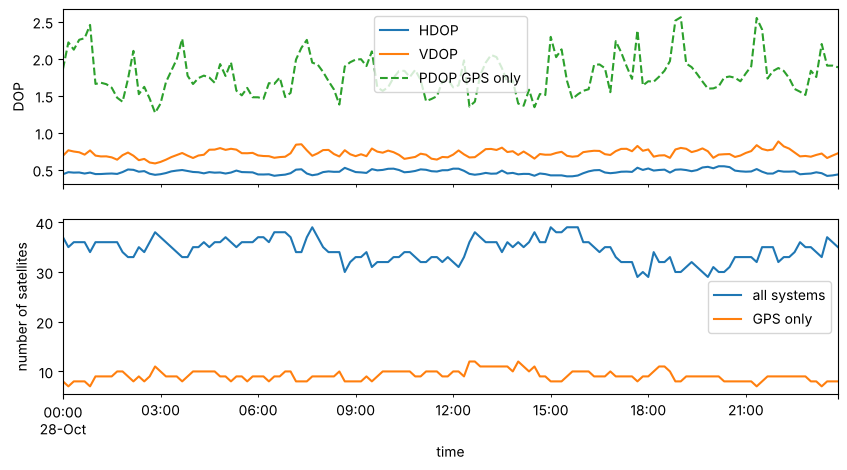

     HDOP  VDOP  PDOP  satellites
min  0.41  0.58  0.73        29.0
50%  0.47  0.71  0.86        35.0
max  0.55  0.88  1.01        39.0


In [5]:
def dop(df, systems=("GPS", "Galileo", "GLONASS", "BeiDou")):
    df = df[df.system.isin(systems)]
    if len(df) < 4 + df.system.nunique() - 1:
        return np.nan, np.nan, np.nan, len(df)
    az, el = np.radians(df.az.values), np.radians(df.el.values)
    G = np.c_[-np.cos(el) * np.sin(az), -np.cos(el) * np.cos(az), -np.sin(el)]
    G = np.c_[G, pd.get_dummies(df.system).values.astype(float)]
    Q = np.linalg.inv(G.T @ G)
    return np.sqrt(Q[0, 0] + Q[1, 1]), np.sqrt(Q[2, 2]), np.sqrt(Q[0, 0] + Q[1, 1] + Q[2, 2]), len(df)

def day_series(horizon=lambda az: np.full_like(az, mask, dtype=float), systems=("GPS", "Galileo", "GLONASS", "BeiDou"), lat=LAT, lon=LON, step=10):
    out = []
    for k in range(0, 24 * 60, step):
        tt = T0 + timedelta(minutes=k)
        s = az_el(tt, lat, lon)
        s = s[s.el > horizon(s.az.values)]
        out.append((tt, *dop(s, systems)))
    return pd.DataFrame(out, columns=["time", "HDOP", "VDOP", "PDOP", "satellites"]).set_index("time")

open_sky = day_series()
gps_only = day_series(systems=("GPS",))
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
open_sky[["HDOP", "VDOP"]].plot(ax=ax[0]); gps_only[["PDOP"]].rename(columns={"PDOP": "PDOP GPS only"}).plot(ax=ax[0], ls="--")
open_sky["satellites"].plot(ax=ax[1], label="all systems"); gps_only["satellites"].plot(ax=ax[1], label="GPS only"); ax[1].legend()
ax[0].set_ylabel("DOP"); ax[1].set_ylabel("number of satellites"); plt.show()
print(open_sky.describe().loc[["min", "50%", "max"]].round(2))

> **✏️ Task 2.** Why is VDOP larger than HDOP all day? Explain it by where the satellites are in the sky and where they cannot be. How many satellites does a four-system receiver see and how many with GPS only, and how does that affect PDOP? Set the mask to 20° and then 5°.

*Your answer:* 

## 4. Forest to the south or to the north?

A forest edge blocks the sky up to about 35° on one side. The orbits of GPS (inclination 55°) and Galileo (56°) never go beyond 55–56° latitude, so in central Europe there is a region without satellites in the northern sky at medium elevations. Low above the northern horizon, however, we see satellites passing “beyond the pole”. Which side of the forest hurts more is therefore not obvious and depends on the height of the forest.

In [6]:
forest_el = 35                         # ◀ parameter: height of the forest edge above the horizon (°)
south = lambda az: np.where((az > 90) & (az < 270), forest_el, mask)
north = lambda az: np.where((az < 90) | (az > 270), forest_el, mask)
res = pd.DataFrame({name: day_series(h, step=20).median() for name, h in [("open sky", lambda az: np.full_like(az, mask, float)), ("forest to the south", south), ("forest to the north", north)]})
res.round(2)

,open sky,forest to the south,forest to the north
HDOP,0.46,0.72,0.78
VDOP,0.71,1.03,1.19
PDOP,0.85,1.24,1.40
satellites,35.00,27.00,24.00


> **✏️ Task 3.** Where is the “hole” without satellites in the sky from step 2, and why? Try forest_el 20°, 35° and 60°: does a forest to the north or to the south hurt more? Does the common advice “there is a hole in the north, so a forest to the north does not matter” hold? Explain the result by the elevations at which the northern sky has the hole and those at which it has satellites “beyond the pole” (the sky plot from step 2 at other hours helps; change `T_SKY`). Where would you set up a base station or survey a ground control point?

*Your answer:* 

## 5. A deep valley: the real horizon from DMR 5G

For a point by the Vltava in Roztoky we compute the horizon elevation in every azimuth from the terrain model and use it to select visible satellites.

terrain at the point 183.1 m a.s.l.; horizon 0.3–12.6°


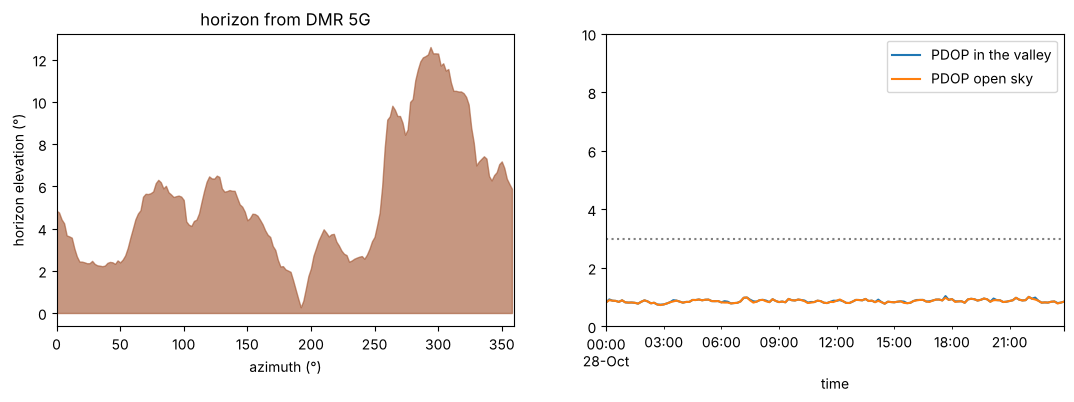

in the valley PDOP < 3 with at least 10 satellites for 24.0 h out of 24 h


In [7]:
VLAT, VLON = 50.1588, 14.3985        # ◀ parameter: point in the valley (by the Vltava in Roztoky)
R_h = 2500
to_sjtsk = Transformer.from_crs(4326, 5514, always_xy=True)
vx, vy = to_sjtsk.transform(VLON, VLAT)
dem, tr = cuzk_raster("dmr5g", vx - R_h, vy - R_h, vx + R_h, vy + R_h, res=10)
row0, col0 = rasterio.transform.rowcol(tr, vx, vy); z0 = dem[row0, col0] + 1.8      # antenna 1.8 m above ground
azs = np.arange(0, 360, 2); dist = np.arange(20, R_h, 10)
hor = []
for a in np.radians(azs):
    xs, ys = vx + dist * np.sin(a), vy + dist * np.cos(a)
    rr, cc = rasterio.transform.rowcol(tr, xs, ys)
    hor.append(np.degrees(np.arctan2(dem[np.array(rr), np.array(cc)] - z0, dist)).max())
hor = np.maximum(np.array(hor), 0)
valley = lambda az: np.maximum(np.interp(az, azs, hor, period=360), mask)
print(f"terrain at the point {dem[row0, col0]:.1f} m a.s.l.; horizon {hor.min():.1f}–{hor.max():.1f}°")
v_day = day_series(valley, lat=VLAT, lon=VLON, step=10)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].fill_between(azs, 0, hor, color="sienna", alpha=0.6); ax[0].set(xlabel="azimuth (°)", ylabel="horizon elevation (°)", xlim=(0, 360), title="horizon from DMR 5G")
v_day.PDOP.plot(ax=ax[1], label="PDOP in the valley"); open_sky.PDOP.plot(ax=ax[1], label="PDOP open sky"); ax[1].axhline(3, color="gray", ls=":")
ax[1].set_ylim(0, 10); ax[1].legend(); plt.show()
good = v_day[(v_day.PDOP < 3) & (v_day.satellites >= 10)]
print(f"in the valley PDOP < 3 with at least 10 satellites for {len(good) * 10 / 60:.1f} h out of 24 h")

> **✏️ Task 4.** Which directions does the valley block most and why? How high does the horizon reach, and is the valley really “deep” for a four-system GNSS receiver? Try `mask = 20` or a point below a rock face. At which hours of the selected day (UTC) would you survey ground control points in the valley? Why does the terrain model not capture everything that actually blocks or reflects the signal (trees, buildings, rock faces)?

*Your answer:* 

## 6. CZEPOS reference stations

RTK accuracy decreases with distance from the reference station because ionospheric, tropospheric and orbit effects decorrelate. Manufacturers usually state accuracy as 1 cm + 1 ppm (1 mm per km).

In [8]:
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/0/query",
                 params={"where": "1=1", "outFields": "NAZEV_BODU,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
cz = pd.DataFrame([f["attributes"] for f in q["features"]])
cz["km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin(np.radians(cz.B - LAT) / 2) ** 2 + np.cos(np.radians(LAT)) * np.cos(np.radians(cz.B)) * np.sin(np.radians(cz.L - LON) / 2) ** 2))
cz["RTK horiz. (mm)"] = 10 + 1.0 * cz.km
print(f"CZEPOS stations: {len(cz)}")
cz.sort_values("km").head(5).round(2)

CZEPOS stations: 29


,NAZEV_BODU,B,L,HEL,NAZEV_KU,km,RTK horiz. (mm)
16,CPRG,50.13,14.46,356.02,Kobylisy,5.94,15.94
24,GOPE,49.91,14.79,592.60,Ondřejov u Prahy,38.05,48.05
18,CRAK,50.10,13.73,381.87,Rakovník,46.00,56.00
12,CLIT,50.54,14.14,243.28,Litoměřice,48.52,58.52
13,CMBO,50.41,14.91,303.46,Mladá Boleslav,49.24,59.24


## 7. Ellipsoidal height or Bpv?

RTK gives height above the GRS80 ellipsoid (ETRS89). Maps and projects in Czechia use normal height in Bpv. The difference is the height anomaly ζ = h − H. We take densification survey points nearby that have both heights.

points: 45, ζ = 44.461 to 45.367 m, mean 44.906 m


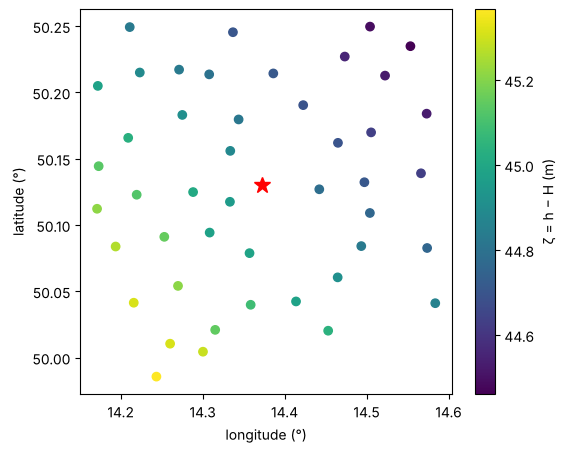

In [9]:
px, py = to_sjtsk.transform(LON, LAT)
half = 15000                       # ◀ parameter: half-width of the surroundings (m)
q = requests.get("https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer/2/query",
                 params={"geometry": f"{px - half},{py - half},{px + half},{py + half}", "geometryType": "esriGeometryEnvelope", "inSR": 5514,
                         "outFields": "CISLO_SMO5,CISLO,Y,X,VYSKA,B,L,HEL,NAZEV_KU", "returnGeometry": "false", "f": "json"}, timeout=60).json()
pts = pd.DataFrame([f["attributes"] for f in q["features"]])
pts["H_Bpv"] = pd.to_numeric(pts.VYSKA, errors="coerce")
pts = pts.dropna(subset=["H_Bpv", "HEL"])
pts["zeta"] = pts.HEL - pts.H_Bpv
print(f"points: {len(pts)}, ζ = {pts.zeta.min():.3f} to {pts.zeta.max():.3f} m, mean {pts.zeta.mean():.3f} m")
fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(pts.L, pts.B, c=pts.zeta, cmap="viridis"); fig.colorbar(sc, label="ζ = h − H (m)")
ax.plot(LON, LAT, "r*", ms=12); ax.set(xlabel="longitude (°)", ylabel="latitude (°)"); plt.show()

> **✏️ Task 5.** What is the height anomaly around Suchdol and how much does it change over 30 km? What happens to a terrain model or to ground control points if you store RTK heights as Bpv without conversion? Why is subtracting one constant for the whole country not enough, and what should you use (quasigeoid model, ČÚZK transformation service)? How far is the nearest CZEPOS station and what RTK error do you expect from that?

*Your answer:* 

---
### Data sources and references

- Broadcast ephemerides: International GNSS Service (IGS), daily merged navigation file BRDC00IGS_R, BKG archive https://igs.bkg.bund.de/root_ftp/IGS/BRDC/ (IGS data are freely available with attribution). Johnston, G., Riddell, A., Hausler, G. (2017). The International GNSS Service. In *Springer Handbook of Global Navigation Satellite Systems*, 967–982.
- Satellite position computation: IS-GPS-200 (GPS interface, sec. 20.3.3.4.3), Galileo OS SIS ICD, BeiDou ICD B1I (geostationary satellites), GLONASS ICD (integration of motion, appendix J); RINEX 3.05 format (IGS/RTCM).
- Survey control and CZEPOS stations: © ČÚZK, service https://ags.cuzk.cz/arcgis/rest/services/BodovaPole/MapServer (CC BY 4.0).
- DMR 5G: © ČÚZK, CC BY 4.0, https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer
- Hofmann-Wellenhof, B., Lichtenegger, H., Wasle, E. (2008). *GNSS – Global Navigation Satellite Systems*. Springer (DOP, multi-GNSS, RTK).

### How to cite

OpenSkyLab (2026). GNSS under the sky: real satellites, DOP, terrain and Bpv heights [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/gnss_sky_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*